# 01 - Data exploration and cleaning of `train_test.csv`


## 1. Setup

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, preprocessing as pp

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the raw data

In [3]:
train_raw = pp.load_raw(config.TRAIN_RAW)
val_raw = pp.load_raw(config.VALIDATION_RAW)

print("train_test:", train_raw.shape, "| validation:", val_raw.shape)
train_raw.head()

train_test: (48000, 14) | validation: (12000, 13)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [4]:
train_raw.dtypes

load_id                    str
pickup                     str
delivery                   str
pickup_lat             float64
pickup_lon             float64
delivery_lat           float64
delivery_lon           float64
distance               float64
equipment                  str
weight                 float64
date            datetime64[us]
market_index           float64
quote_signal           float64
posted_rate            float64
dtype: object

## 3. Date ranges



In [5]:
for name, df in [("train_test", train_raw), ("validation", val_raw)]:
    print(f"{name:11s} {df['date'].min().date()} -> {df['date'].max().date()}  "
          f"invalid dates: {df['date'].isna().sum()}")

print()
print("Loads per month (train):")
print(train_raw["date"].dt.to_period("M").value_counts().sort_index().to_string())

train_test  2025-01-01 -> 2025-10-31  invalid dates: 0
validation  2025-11-01 -> 2025-12-31  invalid dates: 0

Loads per month (train):
date
2025-01    4918
2025-02    4337
2025-03    5036
2025-04    4819
2025-05    4913
2025-06    4783
2025-07    4912
2025-08    4759
2025-09    4670
2025-10    4853
Freq: M


## 4. Missing values, duplicates and IDs

In [6]:
missing = pd.DataFrame({
    "train_missing": train_raw.isna().sum(),
    "train_%": (train_raw.isna().mean() * 100).round(2),
    "val_missing": val_raw.isna().sum(),
})
missing[(missing.train_missing > 0) | (missing.val_missing > 0)]

,train_missing,train_%,val_missing
market_index,374,0.78,249.0
weight,300,0.62,165.0


In [7]:
print("duplicate load_id (train):", train_raw["load_id"].duplicated().sum())
print("duplicate load_id (val):  ", val_raw["load_id"].duplicated().sum())
print("load_id shared by both:   ", len(set(train_raw["load_id"]) & set(val_raw["load_id"])))
print("duplicate rows ignoring load_id (train):", train_raw.drop(columns="load_id").duplicated().sum())

duplicate load_id (train): 0
duplicate load_id (val):   0
load_id shared by both:    0
duplicate rows ignoring load_id (train): 0


In [8]:
# Is the missingness related to anything (time, equipment)? If not, simple imputation is safe.
tmp = train_raw.assign(month=train_raw["date"].dt.to_period("M"))
print(tmp.groupby("month")["weight"].apply(lambda s: s.isna().mean()).round(4).to_string())
print()
print(tmp.groupby("equipment")["weight"].apply(lambda s: s.isna().mean()).round(4).to_string())

month
2025-01    0.0069
2025-02    0.0076
2025-03    0.0071
2025-04    0.0042
2025-05    0.0045
2025-06    0.0067
2025-07    0.0059
2025-08    0.0061
2025-09    0.0071
2025-10    0.0066
Freq: M

equipment
Dry Van    0.0064
Flatbed    0.0063
Reefer     0.0058


**Finding:** `weight` is missing in 0.6% of train rows and `market_index` in 0.8%. The missingness is spread
evenly over months and equipment, so it looks random. No duplicates and no ID overlap.
`market_index` and `quote_signal` are dropped by design, so only `weight` needs imputing.

## 5. Categorical columns

In [9]:
print(train_raw["equipment"].value_counts(dropna=False))
print()
# stray whitespace / case problems?
for col in ["pickup", "delivery", "equipment"]:
    s = train_raw[col]
    print(f"{col:9s} unique={s.nunique():3d}  needs strip={(s != s.str.strip()).sum()}")

equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

pickup    unique= 64  needs strip=0
delivery  unique= 64  needs strip=0
equipment unique=  3  needs strip=0


In [10]:
train_cities = set(train_raw["pickup"]) | set(train_raw["delivery"])
val_cities = set(val_raw["pickup"]) | set(val_raw["delivery"])
new_cities = sorted(val_cities - train_cities)
n_rows = (~val_raw["pickup"].isin(train_cities) | ~val_raw["delivery"].isin(train_cities)).sum()
print("cities only in validation:", new_cities)
print("validation rows touching one of them:", n_rows, f"({n_rows / len(val_raw):.1%})")

cities only in validation: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
validation rows touching one of them: 1447 (12.1%)


**Finding:** equipment is clean (3 labels). But 8 cities appear only in validation (12% of its rows), so the model
cannot depend on city or lane identity; it has to rely on distance, equipment, weight and time.

## 6. Weight

In [11]:
w = train_raw["weight"]
print("negative:", (w < 0).sum(), "| zero:", (w == 0).sum(), "| missing:", w.isna().sum())
print()
print("|weight| range:", w.abs().min(), "->", w.abs().max())
print("rows exactly at 47,500 (cap):", (w.abs() == 47_500).sum())
print()
print("mean log-rate gap, negative vs positive weight (should be ~0 if it is just a sign error):")
tmp = train_raw.assign(lr=np.log(train_raw["posted_rate"]), ld=np.log(train_raw["distance"]))
print((tmp[tmp.weight < 0]["lr"] - 0.87 * tmp[tmp.weight < 0]["ld"]).mean()
      - (tmp[tmp.weight > 0]["lr"] - 0.87 * tmp[tmp.weight > 0]["ld"]).mean())

negative: 292 | zero: 0 | missing: 300

|weight| range: 5000.0 -> 47500.0
rows exactly at 47,500 (cap): 1204

mean log-rate gap, negative vs positive weight (should be ~0 if it is just a sign error):
0.0028461188178494634


**Finding:** 292 negative weights whose absolute values look like normal loads (5,000 to 47,500 lb) and whose
rates are no different, so they are sign errors: **take the absolute value**. Missing weights are
**imputed with the train median** and flagged with `weight_missing`.

## 7. Distance

Check that `distance` is usable and how it relates to the coordinates.

In [12]:
def haversine_miles(lat1, lon1, lat2, lon2):
    r = 3958.8
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

d = train_raw.assign(hav=haversine_miles(train_raw.pickup_lat, train_raw.pickup_lon,
                                         train_raw.delivery_lat, train_raw.delivery_lon))
d["ratio"] = d["distance"] / d["hav"]

print("distance <= 0:", (d.distance <= 0).sum(), "| pickup == delivery:", (d.pickup == d.delivery).sum())
print("distance == 70 (floor):", (d.distance == 70).sum())
print()
print("distance / straight-line distance:")
print(d["ratio"].describe().round(3).to_string())
print()
print("coordinates per city (should be 1):",
      pd.concat([train_raw[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["c", "la", "lo"], axis=1),
                 train_raw[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["c", "la", "lo"], axis=1)])
      .groupby("c")[["la", "lo"]].nunique().max().to_dict())

distance <= 0: 0 | pickup == delivery: 0
distance == 70 (floor): 48

distance / straight-line distance:
count    48000.000
mean         1.195
std          0.144
min          1.058
25%          1.165
50%          1.182
75%          1.205
max          9.635

coordinates per city (should be 1): {'la': 1, 'lo': 1}


**Finding:** `distance` is road distance (about 1.18x the straight line) with a **70-mile floor**.
Coordinates are fixed per city but approximate, and a few city pairs are much closer in coordinates than in
distance. So we **keep `distance` as given** and do not recompute it from coordinates. No fix needed.

## 8. Target: corrupted `posted_rate` values

Rate per mile alone is not enough to spot bad labels because it depends on distance and equipment. So we fit a
robust line `log(rate) ~ equipment + log(distance)` and look at how far each row lies from it.

In [13]:
params = pp.fit_params(train_raw)                       # weight median (train only)
line = pp.fit_robust_rate_line(train_raw)               # robust rate line (train only)
resid = pp.log_rate_residual(train_raw, line)

print("robust spread of normal rows (log units):", round(line["mad_std"], 3))
print("residual quantiles:")
print(resid.quantile([0.001, 0.01, 0.5, 0.99, 0.999]).round(3).to_string())

robust spread of normal rows (log units): 0.052
residual quantiles:
0.001   -1.61
0.010   -0.14
0.500    0.00
0.990    0.13
0.999    1.52


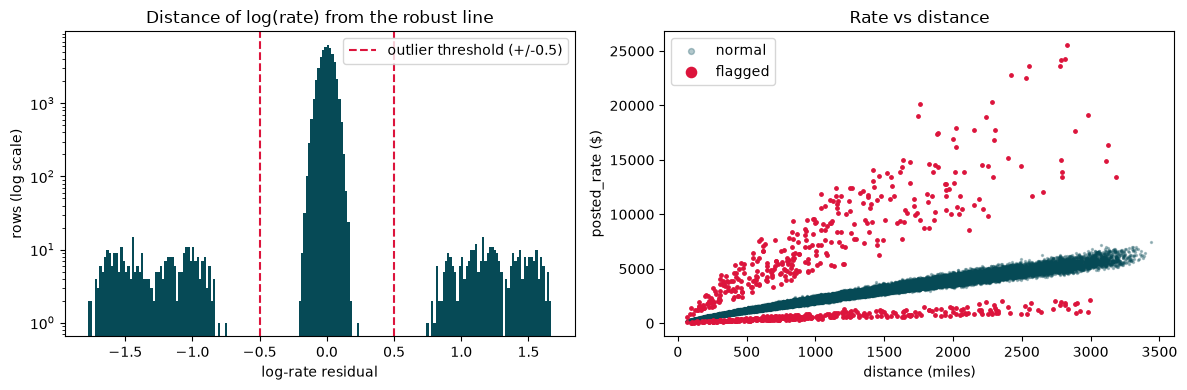

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(resid, bins=200, color="#064A56")
axes[0].set_yscale("log")
axes[0].axvline(config.OUTLIER_LOG_THRESHOLD, color="crimson", ls="--")
axes[0].axvline(-config.OUTLIER_LOG_THRESHOLD, color="crimson", ls="--", label="outlier threshold (+/-0.5)")
axes[0].set_title("Distance of log(rate) from the robust line")
axes[0].set_xlabel("log-rate residual")
axes[0].set_ylabel("rows (log scale)")
axes[0].legend()

is_out = pp.flag_label_outliers(train_raw, line)
axes[1].scatter(train_raw.loc[~is_out, "distance"], train_raw.loc[~is_out, "posted_rate"], s=2, alpha=0.3, color="#064A56", label="normal")
axes[1].scatter(train_raw.loc[is_out, "distance"], train_raw.loc[is_out, "posted_rate"], s=6, color="crimson", label="flagged")
axes[1].set_title("Rate vs distance")
axes[1].set_xlabel("distance (miles)")
axes[1].set_ylabel("posted_rate ($)")
axes[1].legend(markerscale=3)

fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "label_outliers.png", dpi=150)
plt.show()

In [15]:
gap = resid[(resid.abs() > 0.3) & (resid.abs() < 0.7)]
print("rows between 0.3 and 0.7 from the line (the gap):", len(gap))
print("flagged rows:", int(is_out.sum()), f"({is_out.mean():.2%})")
print("  too high:", int((resid[is_out] > 0).sum()), "-> rate is", np.exp(resid[is_out & (resid > 0)]).min().round(1), "to",
      np.exp(resid[is_out & (resid > 0)]).max().round(1), "x the normal level")
print("  too low: ", int((resid[is_out] < 0).sum()), "-> rate is", np.exp(resid[is_out & (resid < 0)]).min().round(2), "to",
      np.exp(resid[is_out & (resid < 0)]).max().round(2), "x the normal level")
print()
print("Flagged rows by month:")
print(train_raw[is_out].groupby(train_raw["date"].dt.to_period("M")).size().to_string())
print("Flagged rows by equipment:")
print(train_raw[is_out]["equipment"].value_counts().to_string())

rows between 0.3 and 0.7 from the line (the gap): 0
flagged rows: 677 (1.41%)
  too high: 340 -> rate is 2.1 to 5.3 x the normal level
  too low:  337 -> rate is 0.17 to 0.47 x the normal level

Flagged rows by month:
date
2025-01    81
2025-02    57
2025-03    71
2025-04    66
2025-05    62
2025-06    63
2025-07    65
2025-08    68
2025-09    64
2025-10    80
Freq: M
Flagged rows by equipment:
equipment
Dry Van    368
Reefer     182
Flatbed    127


**Finding:** normal rows stay within about +/-0.15 of the line, and **no row lies between 0.3 and 0.7**, so the
bad labels are cleanly separated: 677 rows (1.4%), of which 340 are 2.1 to 5.3 times too high and 337 are only
0.17 to 0.47 times the normal level. They appear evenly in every month, equipment type and distance range, so they are not
predictable from the features. **Fix:** remove them from the training data (they are kept in a separate file so
the holdout can also be scored with them).

## 9. Apply the cleaning

In [16]:
# 1) row-preserving feature cleaning (same function will run on validation and December)
train_feat = pp.clean_features(train_raw, params)

# 2) split off the corrupted labels
label_outliers = train_feat[is_out].copy()
train_clean = train_feat[~is_out].copy().reset_index(drop=True)

print("raw rows:      ", len(train_raw))
print("flagged rows:  ", len(label_outliers))
print("clean rows:    ", len(train_clean))
train_clean.head()

raw rows:       48000
flagged rows:   677
clean rows:     47323


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,posted_rate,weight_missing
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,645.41,0
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,679.97,0
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1802.54,0
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,1827.28,0
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,1380.28,0


## 10. Verify the cleaned data

In [17]:
pp.assert_clean(train_clean, labeled=True)
print("All checks passed.\n")

checks = pd.DataFrame({
    "before": [
        (train_raw.weight < 0).sum(),
        train_raw.weight.isna().sum(),
        train_raw.market_index.isna().sum(),
        len(train_raw),
        train_raw.posted_rate.max(),
        (train_raw.posted_rate / train_raw.distance).max(),
    ],
    "after": [
        (train_clean.weight < 0).sum(),
        train_clean.weight.isna().sum(),
        "dropped",
        len(train_clean),
        train_clean.posted_rate.max(),
        (train_clean.posted_rate / train_clean.distance).max(),
    ],
}, index=["negative weights", "missing weight", "missing market_index", "rows", "max posted_rate", "max rate per mile"])
checks

All checks passed.



,before,after
negative weights,292.000000,0
missing weight,300.000000,0
missing market_index,374.000000,dropped
rows,48000.000000,47323
max posted_rate,25533.000000,7498.05
max rate per mile,14.125294,3.571741


In [18]:
print(train_clean.describe().T[["count", "mean", "min", "max"]].round(2))
print()
print("columns:", list(train_clean.columns))

                  count                        mean                  min                  max
pickup_lat      47323.0                   35.645701             28.35765             44.30296
pickup_lon      47323.0                  -90.934841           -121.69849                -69.5
delivery_lat    47323.0                   35.641128             28.35765             44.30296
delivery_lon    47323.0                  -90.866336           -121.69849                -69.5
distance        47323.0                 1136.747694                 70.0               3439.8
weight          47323.0                31423.686939               5000.0              47500.0
date              47323  2025-05-31 19:39:44.354330  2025-01-01 00:00:00  2025-10-31 00:00:00
posted_rate     47323.0                  2347.28481               184.55              7498.05
weight_missing  47323.0                    0.006276                  0.0                  1.0

columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'p

## 11. Save outputs

In [19]:
train_clean.to_csv(config.TRAIN_CLEAN, index=False)
label_outliers.to_csv(config.LABEL_OUTLIERS, index=False)
pp.save_params({**params, "rate_line": line, "outlier_log_threshold": config.OUTLIER_LOG_THRESHOLD})

for p in [config.TRAIN_CLEAN, config.LABEL_OUTLIERS, config.CLEANING_PARAMS]:
    print("saved", p.relative_to(config.ROOT))

saved data\processed\train_test_clean.csv
saved data\processed\train_label_outliers.csv
saved data\processed\cleaning_params.json


## 12. Apply the same row-preserving cleaning to `validation.csv`

No row may be dropped here: all 12,000 loads need a prediction.

In [20]:
val_clean = pp.clean_features(val_raw, params)

assert len(val_clean) == len(val_raw) == 12_000
pp.assert_clean(val_clean, labeled=False)
val_clean.to_csv(config.VALIDATION_CLEAN, index=False)

print("validation rows kept:", len(val_clean), "| weight imputed:", int(val_clean.weight_missing.sum()),
      "| negative weights fixed:", int((val_raw.weight < 0).sum()))

validation rows kept: 12000 | weight imputed: 165 | negative weights fixed: 145
